# Fashion-MNIST Giysi Sınıflandırması – CNN
**LBLM368 – Derin Öğrenme ve Sınıflandırma Teknikleri**

Bu defter `src/` klasöründeki modülleri kullanır. Hücreleri yukarıdan aşağıya sırayla çalıştırın.

In [1]:
import os, sys, json
sys.path.insert(0, os.path.abspath('src'))
import numpy as np, torch, matplotlib.pyplot as plt
from data_utils import get_loaders, CLASS_NAMES, MEAN, STD
from models import FashionCNN, SimpleMLP, count_params
from train import train_model, predict, compute_metrics
torch.manual_seed(42)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Cihaz:', device)
%matplotlib inline

Cihaz: cpu


## 1. Veri yükleme ve ön işleme
Görüntüler [0,1] aralığına ölçeklenip standartlaştırılır; eğitim setinin 6.000 örneği doğrulama için ayrılır.

54000 6000 10000


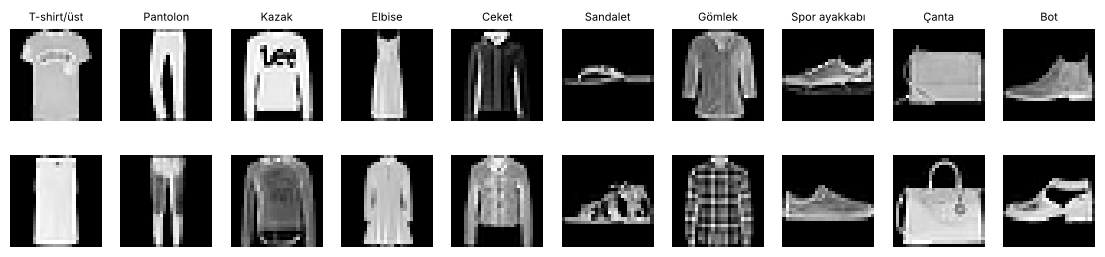

In [2]:
train_loader, val_loader, test_loader = get_loaders('data', batch_size=64)
print(len(train_loader.dataset), len(val_loader.dataset), len(test_loader.dataset))
x, y = test_loader.dataset.tensors
fig, axes = plt.subplots(2, 10, figsize=(14, 3))
for c in range(10):
    for r, i in enumerate(np.where(y.numpy()==c)[0][:2]):
        axes[r,c].imshow((x[i,0]*STD+MEAN).numpy(), cmap='gray'); axes[r,c].axis('off')
        if r==0: axes[r,c].set_title(CLASS_NAMES[c], fontsize=8)
plt.show()

## 2. Model tanımı

In [3]:
model = FashionCNN().to(device)
print(model)
print('Parametre sayısı:', f'{count_params(model):,}')

FashionCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (7): Dropout(p=0.25, inplace=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_r

## 3. Eğitim
`EGIT = False` ise hazır eğitilmiş ağırlıklar yüklenir (hızlı). `True` yapılırsa model baştan eğitilir (CPU'da ~15 dk).

In [4]:
EGIT = False
ckpt = 'outputs/models/fashion_cnn_best.pt'
if EGIT or not os.path.exists(ckpt):
    os.makedirs('outputs/models', exist_ok=True)
    hist = train_model(model, (train_loader, val_loader, test_loader), epochs=15, lr=1e-3,
                       augment=True, patience=5, device=device, ckpt_path=ckpt, name='CNN')
else:
    model.load_state_dict(torch.load(ckpt, map_location=device))
    hist = json.load(open('outputs/history.json'))
    print('Hazır model yüklendi.')

Hazır model yüklendi.


## 4. Doğruluk ve kayıp grafikleri

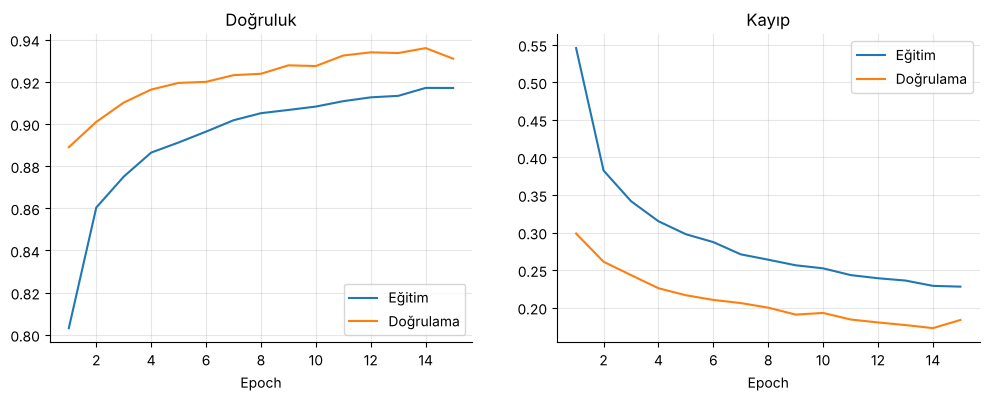

In [5]:
ep = range(1, len(hist['train_loss'])+1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ep, hist['train_acc'], label='Eğitim'); ax[0].plot(ep, hist['val_acc'], label='Doğrulama'); ax[0].set_title('Doğruluk')
ax[1].plot(ep, hist['train_loss'], label='Eğitim'); ax[1].plot(ep, hist['val_loss'], label='Doğrulama'); ax[1].set_title('Kayıp')
for a in ax: a.set_xlabel('Epoch'); a.legend(); a.grid(alpha=.3)
plt.show()

## 5. Test seti değerlendirmesi

{
  "accuracy": 0.9336,
  "precision_macro": 0.9336866152198071,
  "recall_macro": 0.9336,
  "f1_macro": 0.9334273090879697
}
               precision    recall  f1-score   support

  T-shirt/üst     0.8750    0.9030    0.8888      1000
     Pantolon     0.9960    0.9870    0.9915      1000
        Kazak     0.9326    0.8850    0.9082      1000
       Elbise     0.9035    0.9550    0.9285      1000
        Ceket     0.8939    0.9100    0.9019      1000
     Sandalet     0.9860    0.9870    0.9865      1000
       Gömlek     0.8135    0.7810    0.7969      1000
Spor ayakkabı     0.9607    0.9790    0.9698      1000
        Çanta     0.9960    0.9850    0.9904      1000
          Bot     0.9797    0.9640    0.9718      1000

     accuracy                         0.9336     10000
    macro avg     0.9337    0.9336    0.9334     10000
 weighted avg     0.9337    0.9336    0.9334     10000



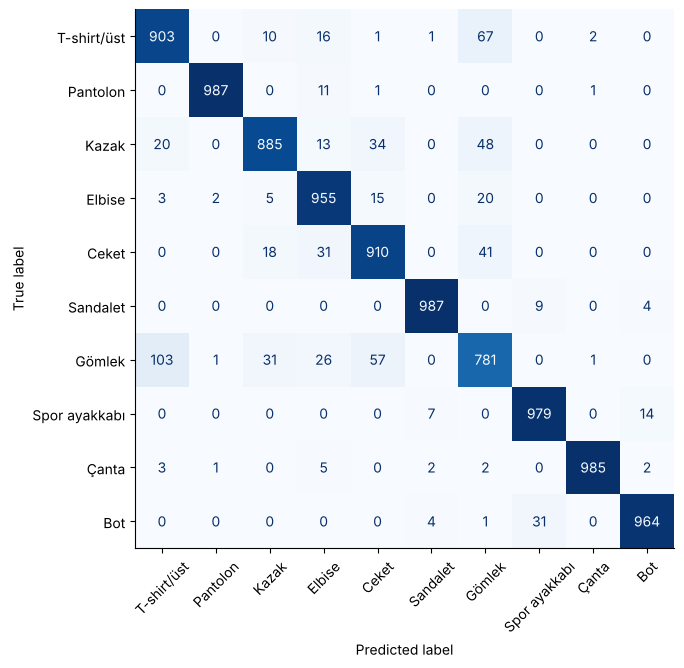

In [6]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
y_pred, y_prob, y_true = predict(model, test_loader, device)
print(json.dumps(compute_metrics(y_true, y_pred), indent=2))
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=CLASS_NAMES, cmap='Blues', ax=ax, xticks_rotation=45, colorbar=False)
plt.show()

## 6. Örnek tahminler (yeşil = doğru, kırmızı = yanlış)

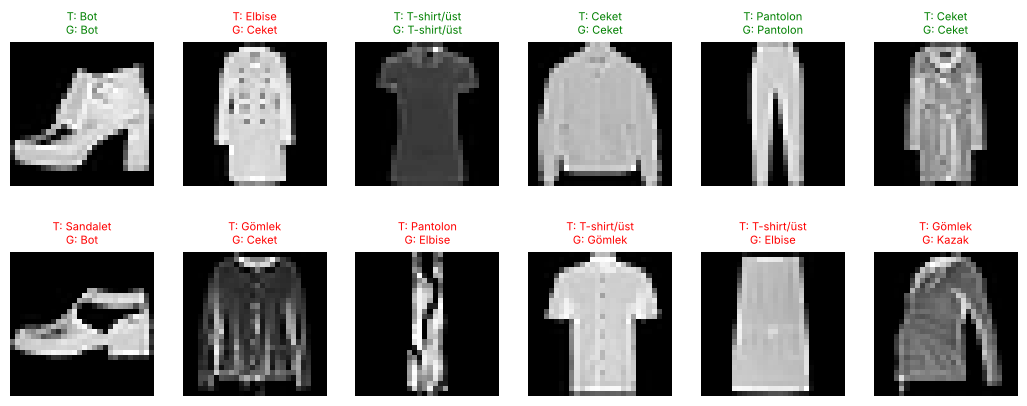

In [7]:
idx = np.random.default_rng(1).choice(len(y_true), 12, replace=False)
wrong = np.where(y_pred != y_true)[0][:6]
idx = np.concatenate([idx[:6], wrong])
fig, axes = plt.subplots(2, 6, figsize=(13, 5))
for a, i in zip(axes.flat, idx):
    a.imshow((x[i,0]*STD+MEAN).numpy(), cmap='gray'); a.axis('off')
    a.set_title(f'T: {CLASS_NAMES[y_pred[i]]}\nG: {CLASS_NAMES[y_true[i]]}', fontsize=8, color='green' if y_pred[i]==y_true[i] else 'red')
plt.show()

## 7. Temel modellerle karşılaştırma

In [8]:
if os.path.exists('outputs/metrics.json'):
    res = json.load(open('outputs/metrics.json'))
    for k, v in res.items():
        print(f"{k:<25} doğruluk={v['accuracy']:.4f}  F1={v['f1_macro']:.4f}")

CNN (bu proje)            doğruluk=0.9336  F1=0.9334
Lojistik Regresyon        doğruluk=0.8432  F1=0.8423
MLP (2 gizli katman)      doğruluk=0.8946  F1=0.8933
